# **ML Development Cycle and Problem Framing**

This notebook follows the steps for building an ML product, then applies them to a small placement example and a churn-planning example. The main idea is to define the problem and data clearly before choosing a model.

<!-- Source transcription: transcription/4.4.md -->
## **Machine Learning Development Life Cycle**

The MLDLC is a practical guide for building an ML product, from deciding what to solve to monitoring it after deployment. Each step answers a different question, and testing can send the team back to the step that needs work.

<!-- Source transcription: transcription/4.4.md -->
### **1. Frame the problem**

Decide what needs to be solved, who will use the result, where the data will come from, and how the model will run. Also consider the team, cost, and the kind of model that fits the task. Agree on what success means before training, so the team can judge whether the result is useful.

<!-- Source transcription: transcription/4.4.md -->
### **2. Gather data**

Data can come from CSV files, APIs, web scraping, databases, or Spark clusters. Database records may pass through a warehouse and ETL (extract, transform, load) before they are stored in a model-ready format.

<!-- Source transcription: transcription/5.1.md -->
### **3. Preprocess the data**

Fix missing values, outliers, noise, duplicates, inconsistent formats, and mismatched columns. Scale numerical values when the chosen model needs features on comparable scales.

<!-- Source transcription: transcription/5.1.md -->
### **4. Explore the data (EDA)**

Use summaries and plots to understand inputs and their relationships with the target. Check individual features, pairs, combinations, outliers, and class imbalance; spend time here before training.

<!-- Source transcription: transcription/5.1.md -->
### **5. Engineer and select features**

Feature engineering creates useful columns or adds information to existing ones. For example, dates can become a ‘days since last activity’ feature. Feature selection keeps impactful columns, since unnecessary features can add training time without helping the task.

<!-- Source transcription: transcription/5.1.md, transcription/5.2.md -->
### **6. Train, evaluate, and select a model**

Try suitable algorithms and compare them with a metric that matches the task: accuracy for classification, mean squared error for regression, or a clustering measure such as the Dunn index. Tuning settings is hyperparameter tuning; boosting, cascading, and bagging combine models.

<!-- Source transcription: transcription/5.2.md -->
### **7. Deploy the model**

Deployment makes the trained model available through software such as a website or app. A saved model can be loaded by a server-side program and accessed through an API, which lets an app send inputs and receive predictions.

<!-- Source transcription: transcription/5.3.md -->
### **8. Test with users**

Try the model with a small group of trusted users and collect feedback. A/B testing can compare versions; keep the success measure consistent across both groups. If feedback is good, release more broadly, and if not, revisit the steps that may have caused the problem.

<!-- Source transcription: transcription/5.3.md -->
### **9. Optimize and monitor**

Back up the model and data, use load balancing, and automate regular retraining. When real-world data changes, model performance can decline, so monitoring and repeatable updates matter.

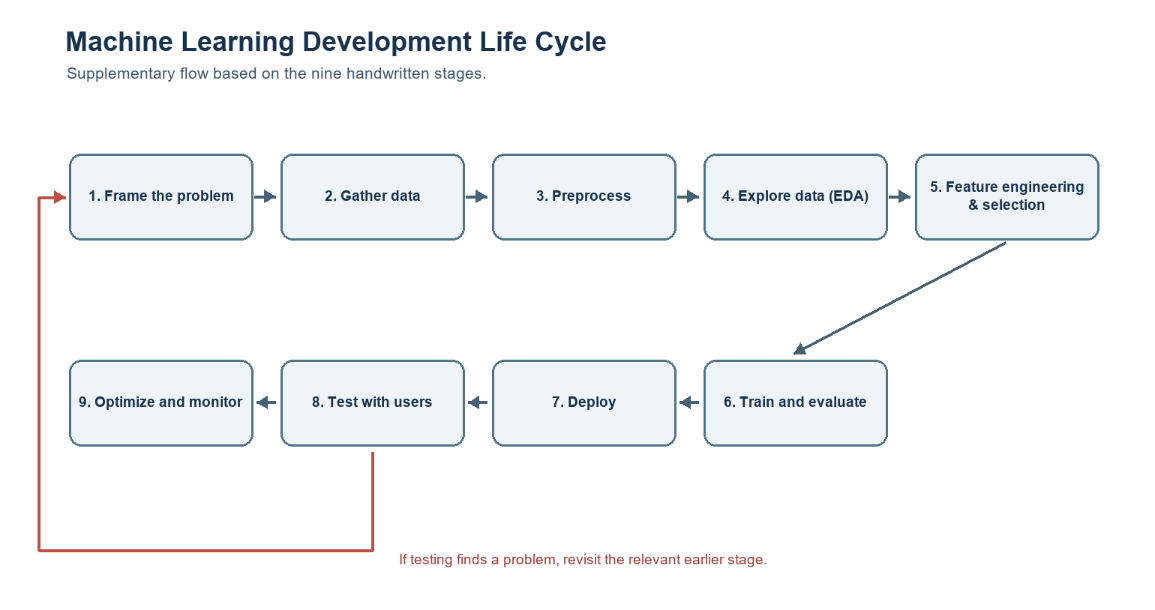

## **A small end-to-end placement example**

This example uses CGPA and IQ as inputs and placement as the target. The dataset below is synthetic, so it demonstrates the workflow rather than making claims about real students; its labels come from a simple rule in the code, not actual placement outcomes.

In [ ]:
import numpy as np

rng = np.random.default_rng(42)
n = 200

cgpa = rng.uniform(2.0, 4.0, n)
iq = rng.normal(100, 15, n)
score = 1.8 * (cgpa - 3.0) + (iq - 100) / 30 + rng.normal(0, 0.45, n)
placed = (score > 0).astype(int)

X = np.column_stack((cgpa, iq))
y = placed

print("Feature matrix shape:", X.shape)
print("Placement counts (0 = not placed, 1 = placed):", np.bincount(y))


Feature matrix shape: (200, 2)
Placement counts (0 = not placed, 1 = placed): [100 100]


X holds the two input columns, while y holds the placement label. Each row in X and the matching value in y describe the same student.

### **Split the data**

Keep a small part aside for testing. This example reserves 10% of the students for evaluation after training, giving a quick check on how the model handles rows it did not learn from.

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.1,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


### **Scale the features**

CGPA and IQ use different scales. Standardizing them helps the model's optimization and regularization treat both features more evenly; fit the scaler on training data only, then apply it to the test data.

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


### **Train the classifier**

Logistic Regression learns a relationship between the inputs and the two placement labels. It can also produce a probability for each label, which a decision threshold turns into a prediction. Here it is used to demonstrate the training step, not to teach the algorithm in detail.

In [ ]:
from sklearn.linear_model import LogisticRegression

clf = LogisticRegression(max_iter=1000)
clf.fit(X_train_scaled, y_train)


### **Evaluate the predictions**

Accuracy compares the predicted labels with the held-out labels. It is a first check; a real project should also inspect whether the chosen metric fits the consequences of each kind of mistake.

In [ ]:
from sklearn.metrics import accuracy_score

y_pred = clf.predict(X_test_scaled)
print(f"Test accuracy: {accuracy_score(y_test, y_pred):.2f}")


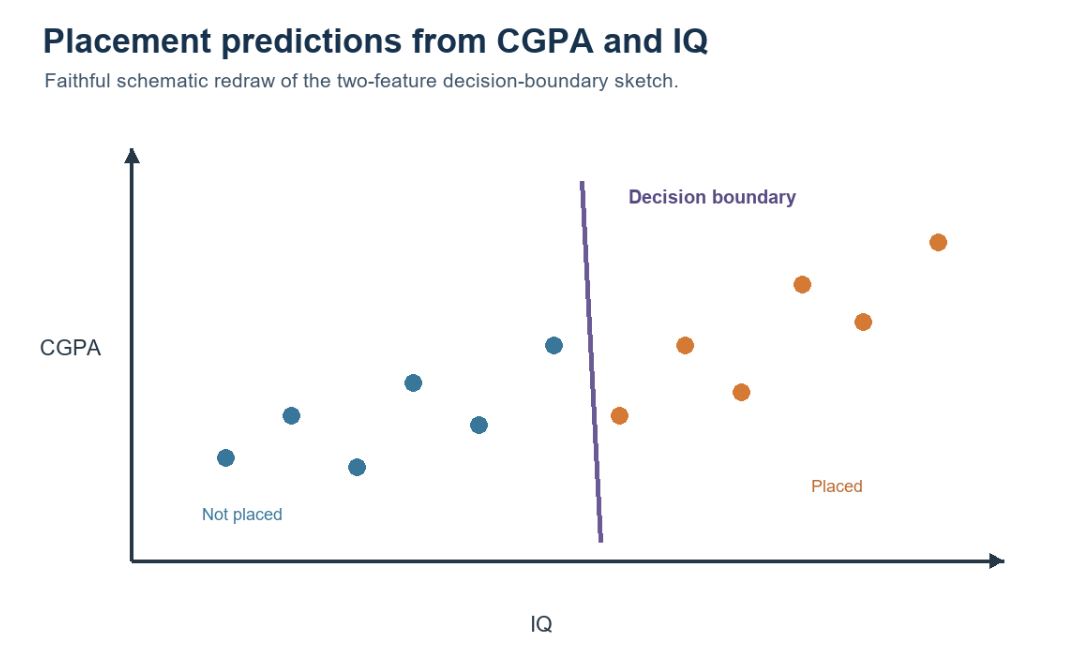

### **Save the model for deployment**

Because this example scales its inputs, the scaler is also needed when new data arrives. Save both together so inference uses the same transformation.

In [ ]:
import pickle

artifact = {"scaler": scaler, "model": clf}
with open("placement_model.pkl", "wb") as file:
    pickle.dump(artifact, file)


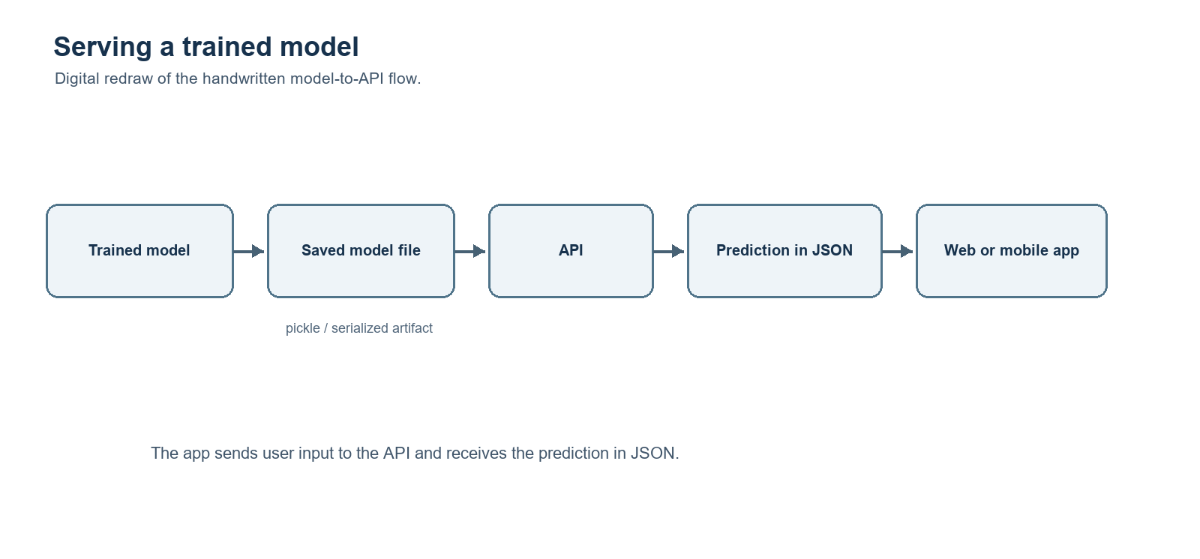

## **Frame a business problem: customer churn**

Start with a business goal, then decide what prediction would help. For example, a team may want to reduce the number of customers who leave a service.

<!-- Source transcription: transcription/7.3.md -->
Churn rate is the share of starting customers who leave during a period:

$$
\text{Churn rate} = \frac{\text{Customers lost during the period}}{\text{Customers at the start of the period}} \times 100\%
$$

If 100 customers start the month and the churn rate is 2%, about 98 remain at the end of that month.

### **1. Turn the business goal into an ML problem**

A sample goal is lowering churn from 4% to 3.75%. The immediate task is to find customers who may leave, so the model predicts a label for each customer.

### **2. Choose the problem type**

A longer study can investigate why customers leave, while a near-term model can flag who may leave soon.


Technical clarification: predicting whether a customer leaves is supervised classification. Regression would fit a numeric target, such as the churn rate itself, rather than a leave/stay label.

<!-- Source transcription: transcription/7.3.md -->
The proposed policy gives a larger discount to customers with a higher predicted chance of leaving and a smaller one to those with a lower chance. Test the discount policy; a prediction alone does not prove it will work.

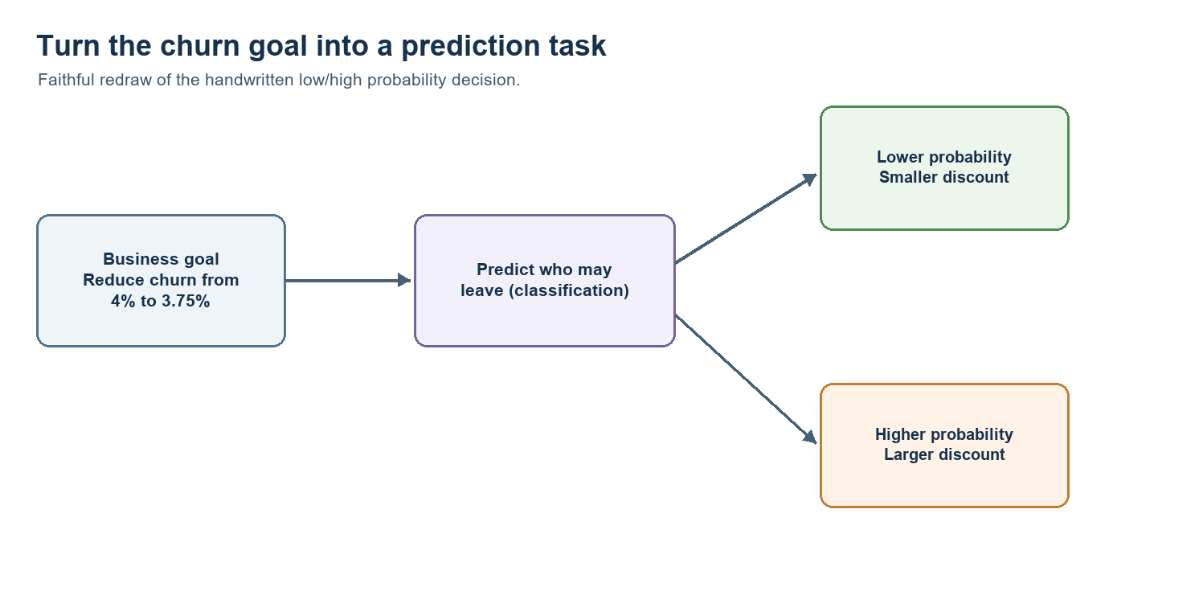

### **3. Check the current solution**

Talk with the people who understand the existing process, such as the CTO or domain experts. If a solution already exists, learn what it does well before replacing it.

### **4. Decide what data is needed**

For churn, useful signals may include watch time, searches that did not find a result, content stopped before the end, and recommendations clicked. These can reveal changes in engagement or friction. Work with data engineers to locate the columns, then prepare a working dataset from the data warehouse.

### **5. Decide how success will be measured**

Compare predicted churn with actual churn, and check whether customers flagged as likely to leave really do leave. Choose the metric before comparing models so the team knows what a useful result means.

### **6. Choose online or batch processing**

Online processing can help when behavior changes quickly, such as during holidays or lockdowns. Batch processing may be a better fit when frequent processing is too difficult or costly; it handles a group of records together on a schedule.

The same workflow applies to both examples: define the target, prepare relevant data, test the model, and plan how its predictions will be used.